# Land Cover Classification — Project Continuation
**RSSI Course Project | Cairo University, Faculty of Engineering**

This notebook continues from `sat_project.ipynb`, which already covers:
- Dataset loading, normalization, and feature engineering (12 bands + 5 spectral indices = 17 features)
- Minimum Distance Classifier (MDC) as a baseline

This notebook adds:
1. **Random Forest** — the main classical ML approach (required by spec)
2. **U-Net** — the deep learning approach (required by spec)
3. **Consolidated evaluation** — mIoU comparison table for all models
4. **Discussion** — analysis of results, trade-offs, and conclusions

> **Run the first notebook (`sat_project.ipynb`) first** so that `scaler.pkl` and the data splits are in memory,
> or re-run the shared setup cells below which reproduce the essential infrastructure.

---
## Cell 1 — Shared Setup
Re-run the data-loading and preprocessing infrastructure so this notebook is self-contained.

In [1]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import joblib
import warnings
warnings.filterwarnings('ignore')

# ── paths ──────────────────────────────────────────────────────────────────────
DATA_FOLDER  = r'S2_ML_Dataset_V2'
MODEL_FOLDER = r'models'
os.makedirs(MODEL_FOLDER, exist_ok=True)

CLASS_NAMES  = ['Greenery', 'Sand', 'Water', 'Cement']
CLASS_LABELS = [1, 2, 3, 4]

TRAIN_LOCS = [
    'BaharyaOasis', 'EasternDesert', 'FarafraOasis', 'KhargaOasis',
    'LibyanBorder', 'SinaiDesert', 'WhiteDesert',
    'AssiutFarms', 'BeheiraNileDelta', 'DakhlaOasis', 'DamietaFarms',
    'HawaraFayoum', 'MiniaFarms', 'NileDelta', 'SohagFarms',
    'WadiNatrun', 'ZagazigFarms',
    'AlexandriaPort', 'CairoDowntown', 'CairoUniv', 'FayoumFarms',
    'GizaPlateau', 'HelwanIndustrial', 'MansouraCity', 'NaserCity',
    'AbuSimbelDesert', 'BardawilLake', 'GreatBitterLake', 'GulfSuez',
    'ManzalaLake', 'NasserLake', 'RedSeaHurghada', 'SaddElAly', 'SuezCanal',
]
VAL_LOCS = [
    'IconicTower', 'QattaraDepression', 'KarnakLuxor', 'SiwaOasis',
    'PortSaidCity', 'ZagazigCity', 'GulfAqaba', 'MariutLake',
]
TEST_LOCS = [
    'QenaFarms', 'TantaCity', 'NileCairo', 'SuezCity',
    'WadiElGemal', 'WadiRum', 'QarunLake', 'TimsahLake',
]


# ── spectral index computation ─────────────────────────────────────────────────
def compute_indices(bands):
    B2  = bands[1].astype(float)
    B3  = bands[2].astype(float)
    B4  = bands[3].astype(float)
    B8  = bands[7].astype(float)
    B8A = bands[8].astype(float)
    B11 = bands[10].astype(float)
    e   = 1e-10
    NDVI     = (B8  - B4)  / (B8  + B4  + e)
    MOISTURE = (B8A - B11) / (B8A + B11 + e)
    NDWI     = (B3  - B8)  / (B3  + B8  + e)
    NDBI     = (B11 - B8)  / (B11 + B8  + e)
    BSI      = ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2) + e)
    return np.stack([NDVI, MOISTURE, NDWI, NDBI, BSI], axis=0)


def load_image_and_mask(location_name):
    img_path  = os.path.join(DATA_FOLDER, location_name + '_12band.tif')
    mask_path = os.path.join(DATA_FOLDER, location_name + '_mask_ESRI.tif')
    with rasterio.open(img_path) as f:
        bands = f.read().astype(np.float32)
    with rasterio.open(mask_path) as f:
        mask = f.read(1)
    H = min(bands.shape[1], mask.shape[0])
    W = min(bands.shape[2], mask.shape[1])
    bands = bands[:, :H, :W]
    mask  = mask[:H, :W]
    bands = np.clip(bands / 10000.0, 0, 1)
    bands = np.nan_to_num(bands, nan=0.0, posinf=0.0, neginf=0.0)
    indices  = compute_indices(bands)
    indices  = np.nan_to_num(indices, nan=0.0, posinf=0.0, neginf=0.0)
    features = np.concatenate([bands, indices], axis=0)   # (17, H, W)
    return features, mask


def get_pixels_from_locations(location_list):
    all_X, all_y = [], []
    for loc in location_list:
        try:
            features, mask = load_image_and_mask(loc)
            X = features.reshape(features.shape[0], -1).T
            y = mask.flatten()
            labeled = y > 0
            X, y    = X[labeled], y[labeled]
            clean   = ~np.isnan(X).any(axis=1)
            all_X.append(X[clean])
            all_y.append(y[clean])
        except Exception as ex:
            print(f'  skipping {loc}: {ex}')
    return np.vstack(all_X), np.concatenate(all_y)


def sample_equal_per_class(X, y, n=600_000, seed=42):
    rng = np.random.RandomState(seed)
    X_out, y_out = [], []
    for label, name in zip(CLASS_LABELS, CLASS_NAMES):
        idx  = np.where(y == label)[0]
        take = min(len(idx), n)
        chosen = rng.choice(idx, take, replace=False)
        X_out.append(X[chosen]);  y_out.append(y[chosen])
        print(f'  {name}: {take:,}')
    return np.vstack(X_out), np.concatenate(y_out)


# ── vectorised mIoU ────────────────────────────────────────────────────────────
def compute_miou(true_labels, pred_labels):
    """Fast vectorised IoU — replaces the slow Python loop in the original."""
    iou_scores = {}
    for c in CLASS_LABELS:
        tp = np.sum((pred_labels == c) & (true_labels == c))
        fp = np.sum((pred_labels == c) & (true_labels != c))
        fn = np.sum((pred_labels != c) & (true_labels == c))
        iou_scores[c] = tp / (tp + fp + fn + 1e-10)
    miou = np.mean(list(iou_scores.values()))
    return iou_scores, miou


print('loading training data…')
X_train, y_train = get_pixels_from_locations(TRAIN_LOCS)
print('loading validation data…')
X_val,   y_val   = get_pixels_from_locations(VAL_LOCS)
print('loading test data…')
X_test,  y_test  = get_pixels_from_locations(TEST_LOCS)

print(f'\nTrain : {X_train.shape[0]:,} pixels | {X_train.shape[1]} features')
print(f'Val   : {X_val.shape[0]:,} pixels')
print(f'Test  : {X_test.shape[0]:,} pixels')

print('\nsampling balanced training set…')
X_tr, y_tr = sample_equal_per_class(X_train, y_train, n=900_000)

scaler    = StandardScaler()
X_tr_s    = scaler.fit_transform(X_tr)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)
for arr in (X_tr_s, X_val_s, X_test_s):
    np.nan_to_num(arr, nan=0.0, copy=False)

joblib.dump(scaler, os.path.join(MODEL_FOLDER, 'scaler.pkl'))
print('setup complete.')

loading training data…
loading validation data…
loading test data…

Train : 12,155,966 pixels | 17 features
Val   : 2,861,415 pixels
Test  : 2,861,184 pixels

sampling balanced training set…
  Greenery: 900,000
  Sand: 900,000
  Water: 900,000
  Cement: 900,000
setup complete.


---
## Cell 2 — Classical Approach: Random Forest

Random Forest was chosen as the primary classical classifier because:
- It handles the **mixed feature scales** of raw bands and spectral indices naturally (no need for standardisation, though we still use the scaled set for consistency with the MDC).
- It is inherently **multi-class** and produces feature importances that give physical insight.
- It is robust to the **class imbalance** typical of satellite imagery.

We train on the same 17-feature, class-balanced pixel set used by the MDC so that evaluation is directly comparable.

In [2]:
from sklearn.ensemble import RandomForestClassifier

RF_PATH = os.path.join(MODEL_FOLDER, 'rf_model.pkl')

if os.path.exists(RF_PATH):
    print('loading saved RF model…')
    rf = joblib.load(RF_PATH)
else:
    print('training Random Forest…')
    rf = RandomForestClassifier(
        n_estimators   = 200,      # 200 trees — good accuracy / speed trade-off
        max_depth       = 20,      # limit depth to avoid overfitting on noisy pixels
        min_samples_leaf= 10,      # each leaf must cover ≥10 pixels
        max_features    = 'sqrt',  # standard choice: sqrt(17) ≈ 4 features per split
        class_weight    = 'balanced',
        n_jobs          = -1,      # use all CPU cores
        random_state    = 42,
        verbose         = 1,
    )
    # RF works well on raw (unscaled) features — use X_tr directly
    rf.fit(X_tr, y_tr)
    joblib.dump(rf, RF_PATH)
    print('Random Forest saved.')

print(f'\nmodel: {rf.n_estimators} trees, max_depth={rf.max_depth}')

training Random Forest…


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:  2.2min
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed: 11.4min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed: 12.7min finished


Random Forest saved.

model: 200 trees, max_depth=20


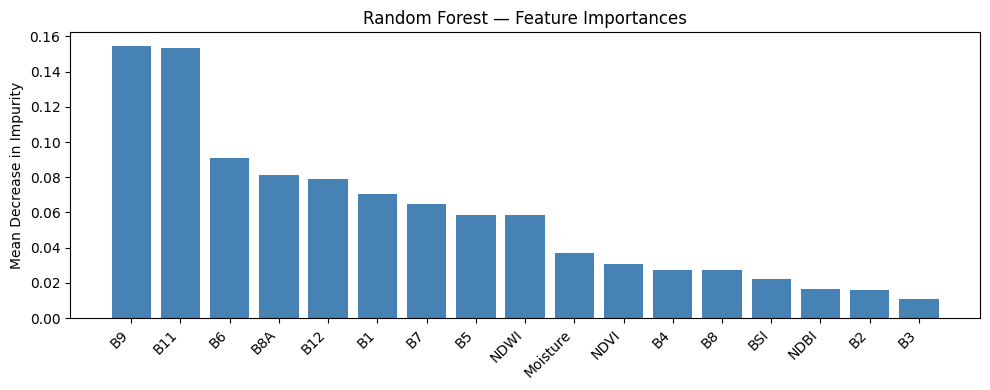

In [3]:
# ── feature importance ─────────────────────────────────────────────────────────
feature_names = [
    'B1','B2','B3','B4','B5','B6','B7','B8','B8A','B9','B11','B12',
    'NDVI','Moisture','NDWI','NDBI','BSI'
]

importances = rf.feature_importances_
order       = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(importances)), importances[order], color='steelblue')
ax.set_xticks(range(len(importances)))
ax.set_xticklabels([feature_names[i] for i in order], rotation=45, ha='right')
ax.set_ylabel('Mean Decrease in Impurity')
ax.set_title('Random Forest — Feature Importances')
plt.tight_layout()
plt.savefig(os.path.join(MODEL_FOLDER, 'rf_feature_importance.png'), dpi=150)
plt.show()


-------------------------------------------------------
  Random Forest | Validation
-------------------------------------------------------


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    2.3s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:   10.4s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:   11.3s finished


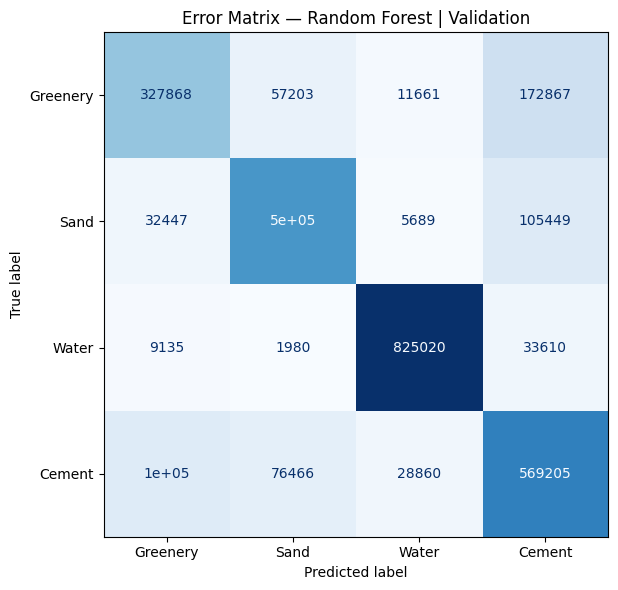

Errors of omission  (missed true pixels):
  Greenery    : 0.4244
  Sand        : 0.2230
  Water       : 0.0514
  Cement      : 0.2686
Errors of commission (false positives):
  Greenery    : 0.3071
  Sand        : 0.2133
  Water       : 0.0530
  Cement      : 0.3540

mIoU = 0.6308
  Greenery    : IoU = 0.4586
  Sand        : IoU = 0.6418
  Water       : IoU = 0.9007
  Cement      : IoU = 0.5221
              precision    recall  f1-score   support

    Greenery       0.69      0.58      0.63    569599
        Sand       0.79      0.78      0.78    643818
       Water       0.95      0.95      0.95    869745
      Cement       0.65      0.73      0.69    778253

    accuracy                           0.78   2861415
   macro avg       0.77      0.76      0.76   2861415
weighted avg       0.78      0.78      0.78   2861415


-------------------------------------------------------
  Random Forest | Test
-------------------------------------------------------


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.6s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    8.4s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    9.4s finished


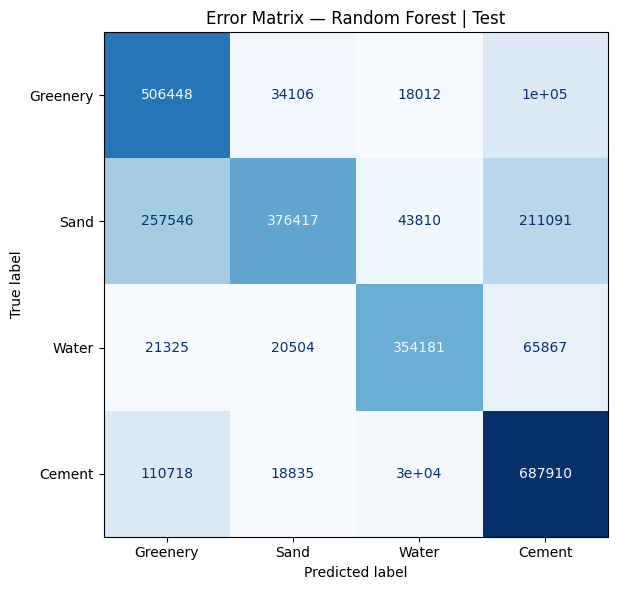

Errors of omission  (missed true pixels):
  Greenery    : 0.2362
  Sand        : 0.5765
  Water       : 0.2332
  Cement      : 0.1882
Errors of commission (false positives):
  Greenery    : 0.4348
  Sand        : 0.1633
  Water       : 0.2057
  Cement      : 0.3567

mIoU = 0.5180
  Greenery    : IoU = 0.4811
  Sand        : IoU = 0.3912
  Water       : IoU = 0.6398
  Cement      : IoU = 0.5598
              precision    recall  f1-score   support

    Greenery       0.57      0.76      0.65    663102
        Sand       0.84      0.42      0.56    888864
       Water       0.79      0.77      0.78    461877
      Cement       0.64      0.81      0.72    847341

    accuracy                           0.67   2861184
   macro avg       0.71      0.69      0.68   2861184
weighted avg       0.71      0.67      0.66   2861184



In [4]:
# ── evaluation helper (reused for RF and U-Net) ────────────────────────────────
def evaluate_model(model_name, predict_fn, splits):
    """
    predict_fn: callable(X) -> y_pred (pixel-level labels)
    splits: list of (split_name, X, y)
    Returns a dict of mIoU scores.
    """
    results = {}
    for split_name, X, y in splits:
        sep = '-' * 55
        print(f'\n{sep}')
        print(f'  {model_name} | {split_name}')
        print(sep)

        pred = predict_fn(X)

        # confusion matrix
        cm  = confusion_matrix(y, pred, labels=CLASS_LABELS)
        fig, ax = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'Error Matrix — {model_name} | {split_name}')
        plt.tight_layout()
        plt.savefig(os.path.join(
            MODEL_FOLDER,
            f'cm_{model_name.lower().replace(" ","_")}_{split_name.lower()}.png'),
            dpi=150)
        plt.show()

        # errors of omission / commission
        print('Errors of omission  (missed true pixels):')
        for i, name in enumerate(CLASS_NAMES):
            err = 1 - cm[i, i] / (cm[i].sum() + 1e-10)
            print(f'  {name:<12}: {err:.4f}')
        print('Errors of commission (false positives):')
        for i, name in enumerate(CLASS_NAMES):
            err = 1 - cm[i, i] / (cm[:, i].sum() + 1e-10)
            print(f'  {name:<12}: {err:.4f}')

        # mIoU
        iou_dict, miou = compute_miou(y, pred)
        print(f'\nmIoU = {miou:.4f}')
        for label, name in zip(CLASS_LABELS, CLASS_NAMES):
            print(f'  {name:<12}: IoU = {iou_dict[label]:.4f}')

        print(classification_report(y, pred,
                                    target_names=CLASS_NAMES,
                                    labels=CLASS_LABELS))
        results[split_name] = (miou, iou_dict)
    return results


# ── run RF evaluation ──────────────────────────────────────────────────────────
rf_results = evaluate_model(
    'Random Forest',
    predict_fn = lambda X: rf.predict(X),   # RF is trained on raw (unscaled) features
    splits = [
        ('Validation', X_val,   y_val),
        ('Test',       X_test,  y_test),
    ]
)

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.5s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.6s finished


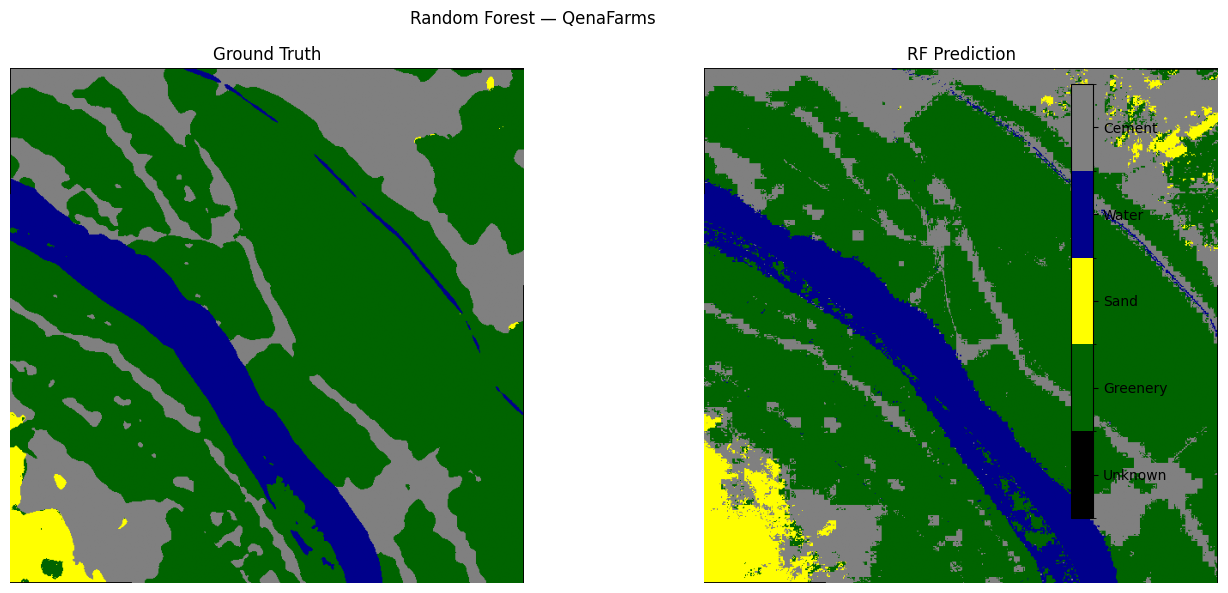

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    3.2s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    3.3s finished


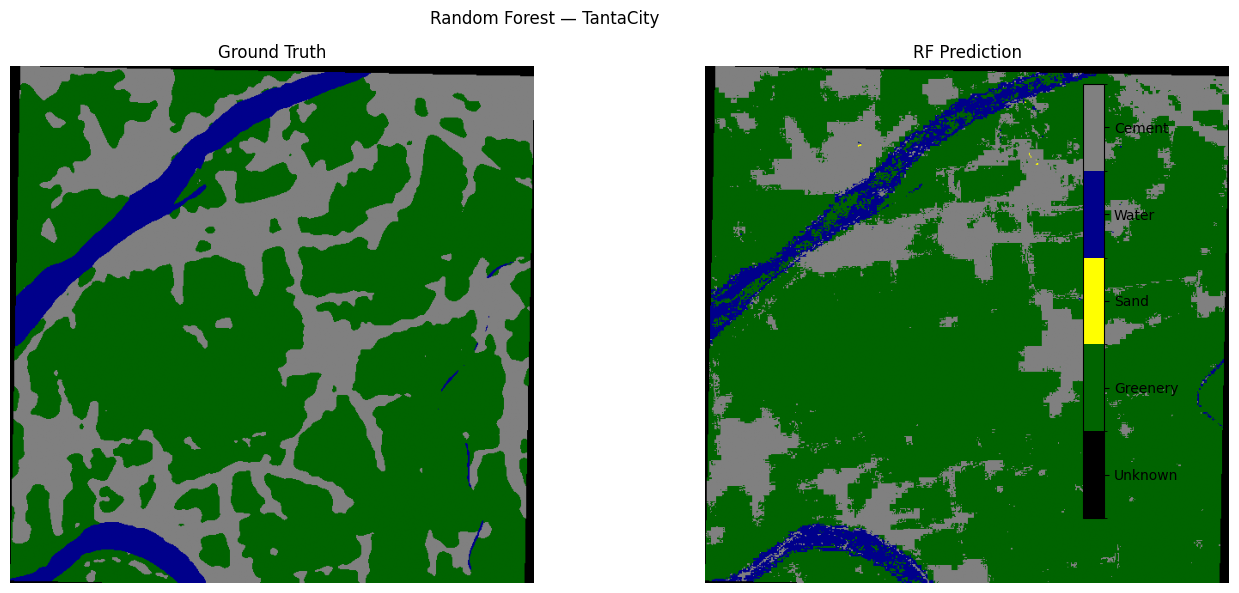

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.2s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    1.1s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    1.3s finished


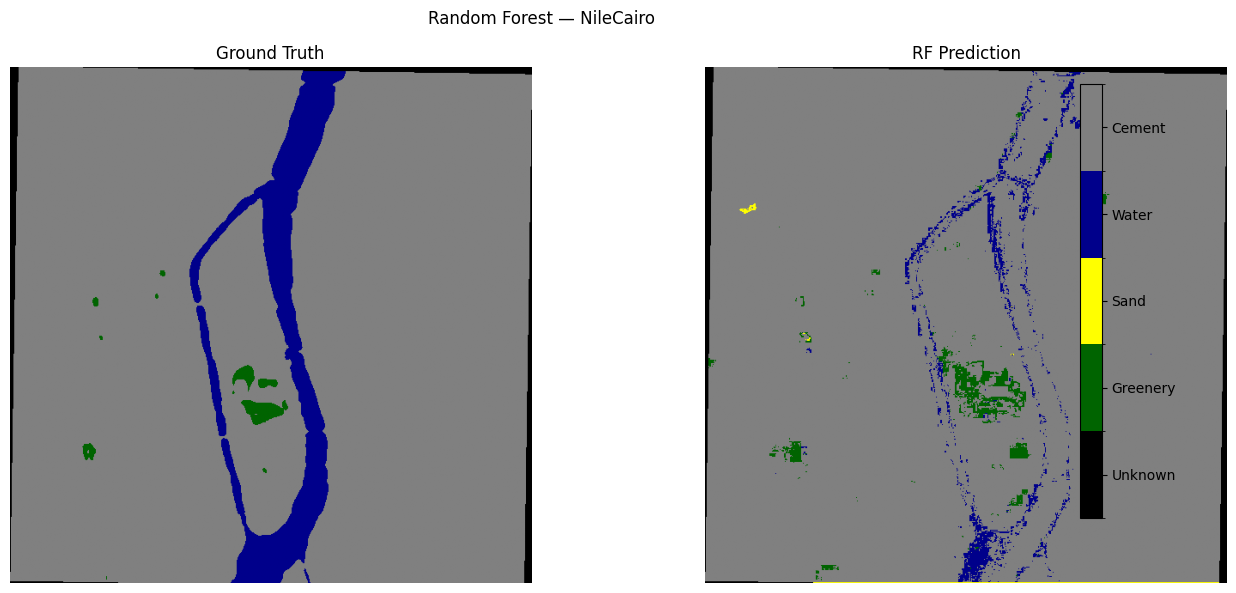

In [5]:
# ── thematic maps for RF ───────────────────────────────────────────────────────
colors = ['black', 'darkgreen', 'yellow', 'darkblue', 'gray']
cmap   = mcolors.ListedColormap(colors)
norm   = mcolors.BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

def make_thematic_map_rf(location_name):
    features, mask = load_image_and_mask(location_name)
    H, W = mask.shape
    X_img   = features.reshape(17, -1).T
    X_clean = np.nan_to_num(X_img, nan=0.0)
    pred    = rf.predict(X_clean).reshape(H, W)
    pred[mask == 0] = 0   # restore unknown border

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(mask, cmap=cmap, norm=norm)
    axes[0].set_title('Ground Truth');   axes[0].axis('off')
    im = axes[1].imshow(pred, cmap=cmap, norm=norm)
    axes[1].set_title('RF Prediction');  axes[1].axis('off')
    cbar = plt.colorbar(im, ax=axes, ticks=[0.5, 1.5, 2.5, 3.5, 4.5],
                        fraction=0.02, pad=0.04)
    cbar.ax.set_yticklabels(['Unknown', 'Greenery', 'Sand', 'Water', 'Cement'])
    plt.suptitle(f'Random Forest — {location_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER, f'rf_{location_name}.png'), dpi=150)
    plt.show()

for loc in TEST_LOCS[:3]:
    make_thematic_map_rf(loc)

---
## Cell 3 — Deep Learning: U-Net

### Architecture choice
**U-Net** is the standard choice for remote-sensing semantic segmentation because:
- Its **encoder–decoder structure with skip connections** preserves fine spatial detail while capturing global context — critical when field boundaries and building edges must be precisely located.
- It was explicitly designed for situations with **limited annotated data**, which matches our ~50 6×6 km tiles.
- It generalises easily to **multi-channel inputs** (we use all 17 feature channels).

### Input representation
Rather than treating each pixel independently (as the classical approaches do), U-Net receives **full image tiles** of shape `(17, H, W)` and produces a segmentation map `(5, H, W)` in one forward pass. This means the network can learn **spatial context** — e.g., that a pixel surrounded by sand is likely sand even if its spectrum is ambiguous.

### Implementation strategy
We implement U-Net using **PyTorch**, patching each GeoTIFF into 128×128 pixel chips with 16-pixel overlap to avoid boundary artefacts at inference time.

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import os

DEVICE     = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE = 128
OVERLAP    = 16
BATCH_SIZE = 16
EPOCHS     = 40
LR         = 3e-4
NUM_CLASSES= 5    # 0-Unknown, 1-Greenery, 2-Sand, 3-Water, 4-Cement
N_FEATURES = 17
UNET_PATH  = os.path.join(MODEL_FOLDER, 'unet_best.pth')

print(f'Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU   : NVIDIA GeForce GTX 1660 Ti with Max-Q Design
VRAM  : 6.0 GB


In [8]:
# ── U-Net architecture ─────────────────────────────────────────────────────────

class DoubleConv(nn.Module):
    """Two consecutive Conv-BN-ReLU blocks — the basic U-Net building block."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """
    Standard U-Net with 4 encoding levels and a bottleneck.
    Encoder channel progression: 17 -> 64 -> 128 -> 256 -> 512 -> 1024
    Decoder mirrors the encoder with skip connections.
    Output: (B, NUM_CLASSES, H, W) logits.
    """
    def __init__(self, in_channels=17, num_classes=5, base=64):
        super().__init__()
        b = base
        # encoder
        self.enc1 = DoubleConv(in_channels, b)
        self.enc2 = DoubleConv(b,    b*2)
        self.enc3 = DoubleConv(b*2,  b*4)
        self.enc4 = DoubleConv(b*4,  b*8)
        self.pool = nn.MaxPool2d(2)
        # bottleneck
        self.bottleneck = DoubleConv(b*8, b*16)
        # decoder
        self.up4   = nn.ConvTranspose2d(b*16, b*8, 2, stride=2)
        self.dec4  = DoubleConv(b*16, b*8)
        self.up3   = nn.ConvTranspose2d(b*8,  b*4, 2, stride=2)
        self.dec3  = DoubleConv(b*8,  b*4)
        self.up2   = nn.ConvTranspose2d(b*4,  b*2, 2, stride=2)
        self.dec2  = DoubleConv(b*4,  b*2)
        self.up1   = nn.ConvTranspose2d(b*2,  b,   2, stride=2)
        self.dec1  = DoubleConv(b*2,  b)
        # output head
        self.out   = nn.Conv2d(b, num_classes, 1)

    def forward(self, x):
        # encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        # bottleneck
        b  = self.bottleneck(self.pool(e4))
        # decoder (each level concatenates with the matching encoder feature map)
        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


model = UNet(in_channels=N_FEATURES, num_classes=NUM_CLASSES).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'U-Net parameters: {total_params:,}')

U-Net parameters: 31,045,957


In [ ]:
# ── patch-based dataset ────────────────────────────────────────────────────────

class PatchDataset(Dataset):
    """
    Slices each GeoTIFF into PATCH_SIZE x PATCH_SIZE tiles.
    Only patches where > 30% of pixels are labelled are kept
    (avoids wasting compute on mostly-unknown border tiles).
    """
    def __init__(self, location_list, patch_size=PATCH_SIZE,
                 augment=False, min_label_ratio=0.30):
        self.patches   = []   # (features_np, mask_np)
        self.augment   = augment
        self.patch_size= patch_size

        for loc in location_list:
            try:
                features, mask = load_image_and_mask(loc)
                H, W           = mask.shape
                for r in range(0, H - patch_size + 1, patch_size):
                    for c in range(0, W - patch_size + 1, patch_size):
                        m_patch = mask[r:r+patch_size, c:c+patch_size]
                        f_patch = features[:, r:r+patch_size, c:c+patch_size]
                        if (m_patch > 0).mean() >= min_label_ratio:
                            self.patches.append((f_patch.copy(), m_patch.copy()))
            except Exception as ex:
                print(f'  skipping {loc}: {ex}')

        print(f'  {len(self.patches):,} patches collected from {len(location_list)} locations')

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        feat, mask = self.patches[idx]
        feat = feat.astype(np.float32)
        mask = mask.astype(np.int64)

        if self.augment:
            # horizontal flip
            if np.random.rand() > 0.5:
                feat = feat[:, :, ::-1].copy()
                mask = mask[:, ::-1].copy()
            # vertical flip
            if np.random.rand() > 0.5:
                feat = feat[:, ::-1, :].copy()
                mask = mask[::-1, :].copy()
            # 90-degree rotation
            k = np.random.randint(0, 4)
            if k:
                feat = np.rot90(feat, k, axes=(1, 2)).copy()
                mask = np.rot90(mask, k).copy()

        return torch.from_numpy(feat), torch.from_numpy(mask)


print('building datasets…')
train_ds = PatchDataset(TRAIN_LOCS, augment=True)
val_ds   = PatchDataset(VAL_LOCS,   augment=False)
test_ds  = PatchDataset(TEST_LOCS,  augment=False)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=4, pin_memory=(DEVICE=='cuda'))
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=2, pin_memory=(DEVICE=='cuda'))
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=2, pin_memory=(DEVICE=='cuda'))

building datasets…
  544 patches collected from 34 locations
  128 patches collected from 8 locations


In [ ]:
# ── loss: Dice + Cross-Entropy combo ──────────────────────────────────────────
# Cross-entropy handles class probability calibration well.
# Dice loss directly optimises the IoU-like overlap score.
# Their combination is standard practice for remote sensing segmentation.

class DiceLoss(nn.Module):
    def __init__(self, num_classes=5, ignore_index=0, smooth=1.0):
        super().__init__()
        self.num_classes   = num_classes
        self.ignore_index  = ignore_index
        self.smooth        = smooth

    def forward(self, logits, targets):
        # logits: (B, C, H, W)   targets: (B, H, W) with values 0..4
        probs = torch.softmax(logits, dim=1)
        # one-hot encode, exclude ignore_index
        valid = targets != self.ignore_index
        dice  = 0.0
        count = 0
        for c in range(1, self.num_classes):   # skip class 0 (Unknown)
            t = (targets == c).float() * valid.float()
            p = probs[:, c] * valid.float()
            inter = (p * t).sum()
            union = p.sum() + t.sum()
            dice += 1 - (2 * inter + self.smooth) / (union + self.smooth)
            count += 1
        return dice / count


ce_loss   = nn.CrossEntropyLoss(ignore_index=0)   # ignore Unknown class
dice_loss = DiceLoss(num_classes=NUM_CLASSES, ignore_index=0)

def combined_loss(logits, targets):
    return ce_loss(logits, targets) + dice_loss(logits, targets)


# ── optimiser and scheduler ───────────────────────────────────────────────────
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
# cosine annealing: smoothly reduces LR to near-zero over training
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Epoch   1/40 | loss 1.2686/1.8762 | mIoU 0.6123/0.2668  ← best
Epoch   2/40 | loss 1.0019/1.4269 | mIoU 0.6671/0.3376  ← best
Epoch   3/40 | loss 0.9412/1.3360 | mIoU 0.6739/0.3461  ← best
Epoch   4/40 | loss 0.8874/1.8124 | mIoU 0.6848/0.2964
Epoch   5/40 | loss 0.8207/1.2392 | mIoU 0.7037/0.3539  ← best
Epoch   6/40 | loss 0.8495/1.2149 | mIoU 0.6787/0.3535
Epoch   7/40 | loss 0.8006/1.1948 | mIoU 0.7061/0.3556  ← best
Epoch   8/40 | loss 0.7826/1.2897 | mIoU 0.7058/0.3378
Epoch   9/40 | loss 0.7618/1.2581 | mIoU 0.7118/0.3613  ← best
Epoch  10/40 | loss 0.7473/1.2447 | mIoU 0.7111/0.3406
Epoch  11/40 | loss 0.7378/1.1588 | mIoU 0.7089/0.3626  ← best
Epoch  12/40 | loss 0.7277/1.1645 | mIoU 0.7155/0.3736  ← best
Epoch  13/40 | loss 0.7346/1.2920 | mIoU 0.7130/0.3433
Epoch  14/40 | loss 0.7107/1.2064 | mIoU 0.7205/0.3596
Epoch  15/40 | loss 0.6988/1.2155 | mIoU 0.7219/0.3564
Epoch  16/40 | loss 0.6925/1.2396 | mIoU 0.7265/0.3405
Epoch  17/40 | loss 0.6903/1.1839 | mIoU 0.7236/0.3598
E

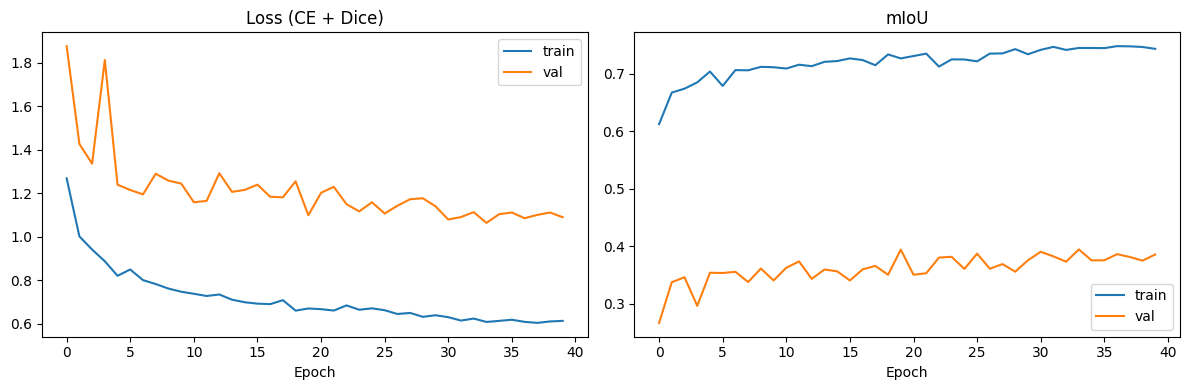

Best val mIoU: 0.3945
U-Net ready.


In [ ]:
# ── training loop ─────────────────────────────────────────────────────────────

def batch_miou(logits, targets):
    """Compute mIoU for one batch (excludes class 0)."""
    pred   = logits.argmax(dim=1).cpu().numpy().flatten()
    true   = targets.cpu().numpy().flatten()
    valid  = true > 0
    if valid.sum() == 0:
        return 0.0
    _, m = compute_miou(true[valid], pred[valid])
    return m


def run_epoch(loader, train=True):
    model.train(train)
    total_loss = 0.0
    total_miou = 0.0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs, masks in loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            logits = model(imgs)
            loss   = combined_loss(logits, masks)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item()
            total_miou += batch_miou(logits, masks)
    n = len(loader)
    return total_loss / n, total_miou / n


if os.path.exists(UNET_PATH):
    print('loading saved U-Net weights…')
    model.load_state_dict(torch.load(UNET_PATH, map_location=DEVICE))
else:
    history = {'train_loss':[], 'val_loss':[], 'train_miou':[], 'val_miou':[]}
    best_val_miou = 0.0

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_miou = run_epoch(train_dl, train=True)
        vl_loss, vl_miou = run_epoch(val_dl,   train=False)
        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_miou'].append(tr_miou)
        history['val_miou'].append(vl_miou)

        if vl_miou > best_val_miou:
            best_val_miou = vl_miou
            torch.save(model.state_dict(), UNET_PATH)
            flag = '  ← best'
        else:
            flag = ''

        print(f'Epoch {epoch:3d}/{EPOCHS} | '
              f'loss {tr_loss:.4f}/{vl_loss:.4f} | '
              f'mIoU {tr_miou:.4f}/{vl_miou:.4f}'
              + flag)

    # plot training curves
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history['train_loss'], label='train')
    ax1.plot(history['val_loss'],   label='val')
    ax1.set_title('Loss (CE + Dice)');  ax1.set_xlabel('Epoch');  ax1.legend()
    ax2.plot(history['train_miou'], label='train')
    ax2.plot(history['val_miou'],   label='val')
    ax2.set_title('mIoU');  ax2.set_xlabel('Epoch');  ax2.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER, 'unet_training_curves.png'), dpi=150)
    plt.show()
    print(f'Best val mIoU: {best_val_miou:.4f}')

# load best weights for evaluation
model.load_state_dict(torch.load(UNET_PATH, map_location=DEVICE))
model.eval()
print('U-Net ready.')

In [ ]:
# ── U-Net evaluation on full images (not patches) ────────────────────────────
# We use a sliding-window approach with overlap to avoid boundary artefacts.

def predict_full_image_unet(location_name, patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    Slide a window over the full GeoTIFF, average logits in overlapping regions,
    then argmax to produce the final segmentation map.
    Returns pred_flat (H*W,) with unknown border masked to 0.
    """
    features, mask = load_image_and_mask(location_name)
    H, W           = mask.shape
    stride         = patch_size - overlap

    # accumulator for logits and count for averaging
    logit_acc = np.zeros((NUM_CLASSES, H, W), dtype=np.float32)
    count_acc = np.zeros((1, H, W),           dtype=np.float32)

    model.eval()
    with torch.no_grad():
        for r in range(0, H, stride):
            for c in range(0, W, stride):
                r2 = min(r + patch_size, H)
                c2 = min(c + patch_size, W)
                r1 = r2 - patch_size
                c1 = c2 - patch_size
                if r1 < 0: r1 = 0
                if c1 < 0: c1 = 0

                patch = features[:, r1:r2, c1:c2]
                ph, pw = patch.shape[1], patch.shape[2]
                # pad if smaller than patch_size
                pad_h = patch_size - ph
                pad_w = patch_size - pw
                if pad_h > 0 or pad_w > 0:
                    patch = np.pad(patch, ((0,0),(0,pad_h),(0,pad_w)))

                t = torch.from_numpy(patch.astype(np.float32)).unsqueeze(0).to(DEVICE)
                logits = model(t).squeeze(0).cpu().numpy()  # (C, P, P)
                logits = logits[:, :ph, :pw]                # remove padding

                logit_acc[:, r1:r1+ph, c1:c1+pw] += logits
                count_acc[:,  r1:r1+ph, c1:c1+pw] += 1

    logit_acc /= np.maximum(count_acc, 1)
    pred = logit_acc.argmax(axis=0)        # (H, W)
    pred[mask == 0] = 0                    # restore unknown border
    return pred, mask


def collect_unet_predictions(location_list):
    """Run full-image U-Net prediction for a list of locations, return flat arrays."""
    all_pred, all_true = [], []
    for loc in location_list:
        try:
            pred, mask = predict_full_image_unet(loc)
            valid      = mask.flatten() > 0
            all_pred.append(pred.flatten()[valid])
            all_true.append(mask.flatten()[valid])
        except Exception as ex:
            print(f'  skipping {loc}: {ex}')
    return np.concatenate(all_pred), np.concatenate(all_true)


print('collecting U-Net predictions on validation set…')
unet_val_pred, unet_val_true = collect_unet_predictions(VAL_LOCS)
print('collecting U-Net predictions on test set…')
unet_test_pred, unet_test_true = collect_unet_predictions(TEST_LOCS)

collecting U-Net predictions on validation set…
collecting U-Net predictions on test set…



-------------------------------------------------------
  U-Net | Validation
-------------------------------------------------------


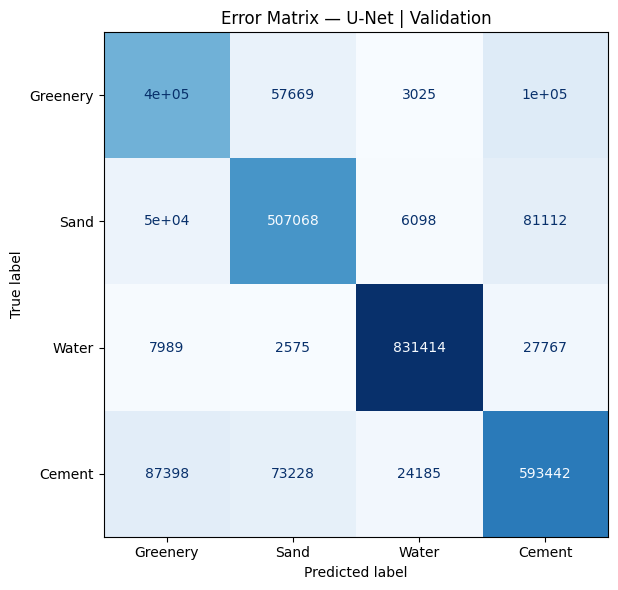

Errors of omission  (missed true pixels):
  Greenery    : 0.2892
  Sand        : 0.2124
  Water       : 0.0441
  Cement      : 0.2375
Errors of commission (false positives):
  Greenery    : 0.2636
  Sand        : 0.2084
  Water       : 0.0385
  Cement      : 0.2640

mIoU = 0.6846
  Greenery    : IoU = 0.5666
  Sand        : IoU = 0.6524
  Water       : IoU = 0.9207
  Cement      : IoU = 0.5987
              precision    recall  f1-score   support

    Greenery       0.74      0.71      0.72    569599
        Sand       0.79      0.79      0.79    643818
       Water       0.96      0.96      0.96    869745
      Cement       0.74      0.76      0.75    778253

    accuracy                           0.82   2861415
   macro avg       0.81      0.80      0.81   2861415
weighted avg       0.82      0.82      0.82   2861415


-------------------------------------------------------
  U-Net | Test
-------------------------------------------------------


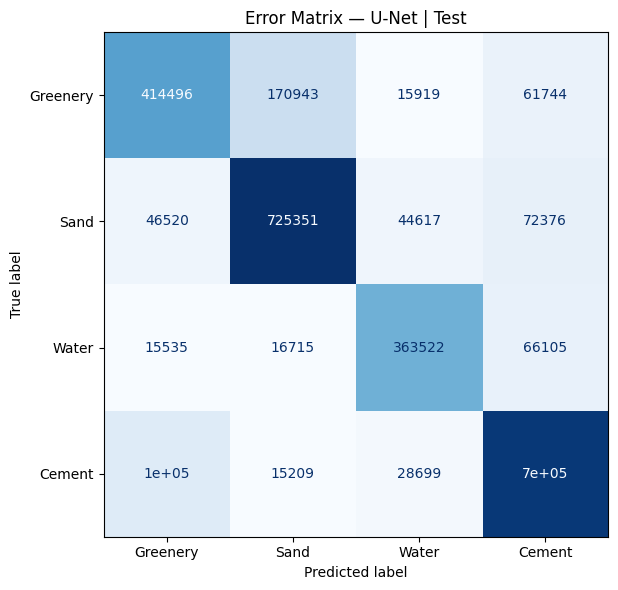

Errors of omission  (missed true pixels):
  Greenery    : 0.3749
  Sand        : 0.1840
  Water       : 0.2129
  Cement      : 0.1726
Errors of commission (false positives):
  Greenery    : 0.2840
  Sand        : 0.2186
  Water       : 0.1971
  Cement      : 0.2221

mIoU = 0.6235
  Greenery    : IoU = 0.5009
  Sand        : IoU = 0.6644
  Water       : IoU = 0.6596
  Cement      : IoU = 0.6693
              precision    recall  f1-score   support

    Greenery       0.72      0.63      0.67    663102
        Sand       0.78      0.82      0.80    888864
       Water       0.80      0.79      0.79    461877
      Cement       0.78      0.83      0.80    847341

    accuracy                           0.77   2861184
   macro avg       0.77      0.76      0.77   2861184
weighted avg       0.77      0.77      0.77   2861184



In [ ]:
# ── U-Net evaluation report ────────────────────────────────────────────────────
unet_results = evaluate_model(
    'U-Net',
    predict_fn = lambda X: X,   # predictions already collected above
    splits = [
        ('Validation', unet_val_pred,  unet_val_true),
        ('Test',       unet_test_pred, unet_test_true),
    ]
)
# Note: evaluate_model calls predict_fn(X) — here X is already the predictions.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# one colour per class: Unknown, Greenery, Sand, Water, Cement
CLASS_COLORS = ['black', 'forestgreen', 'khaki', 'dodgerblue', 'slategray']

cmap = mcolors.ListedColormap(CLASS_COLORS)
norm = mcolors.BoundaryNorm(boundaries=[0, 1, 2, 3, 4, 5], ncolors=5)

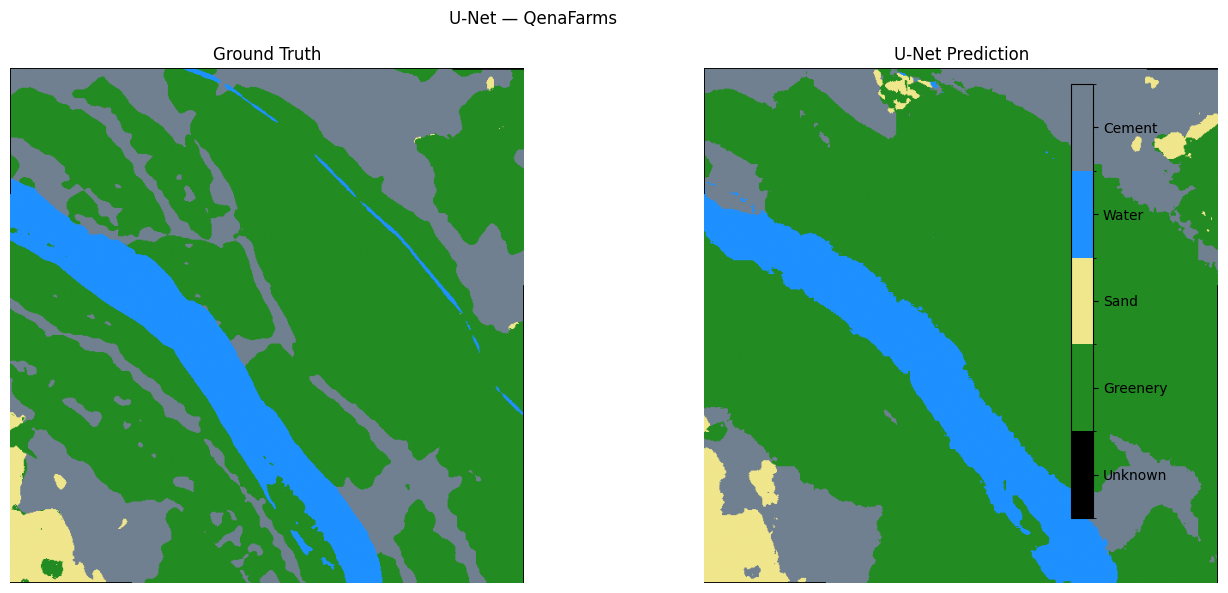

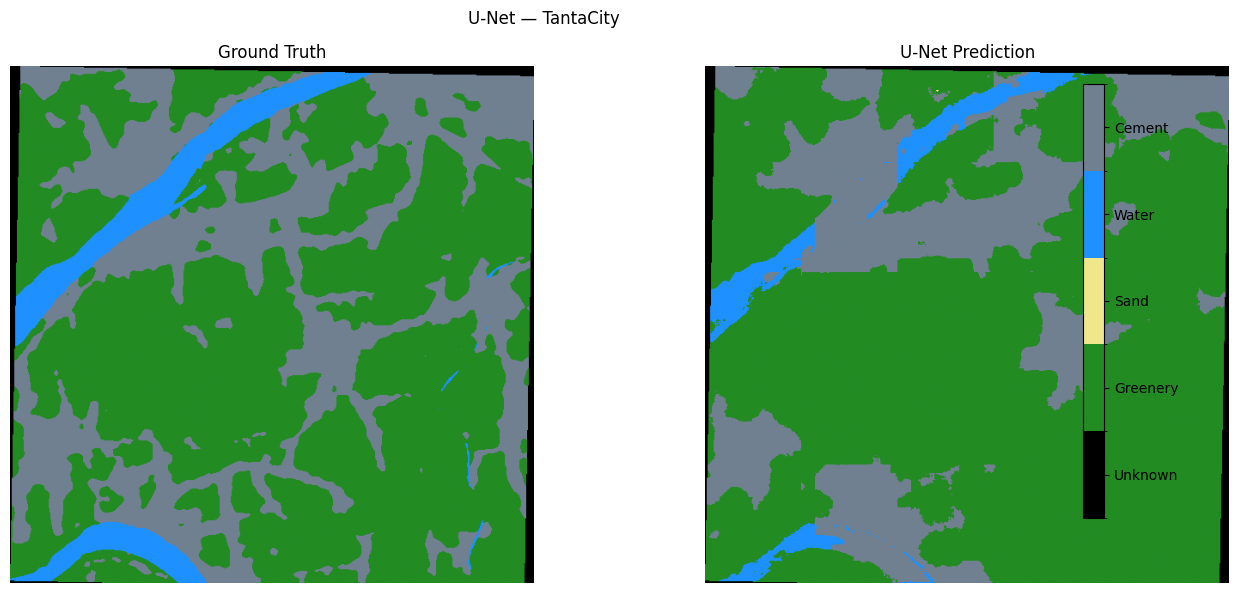

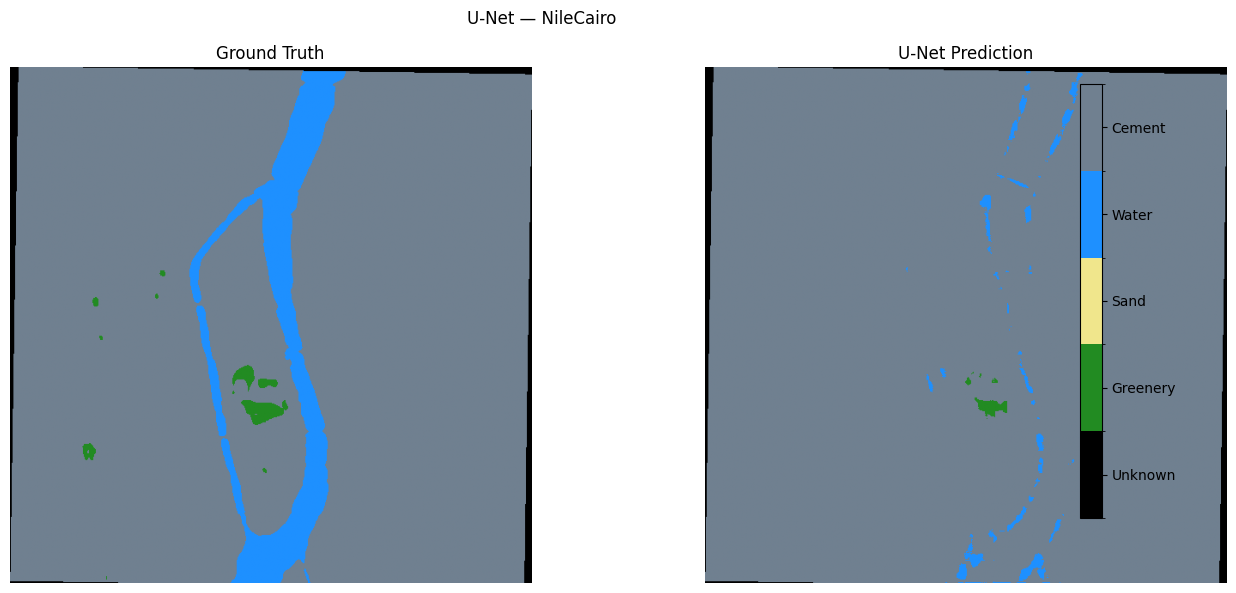

In [ ]:
# ── U-Net thematic maps ────────────────────────────────────────────────────────
def make_thematic_map_unet(location_name):
    pred, mask = predict_full_image_unet(location_name)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(mask, cmap=cmap, norm=norm)
    axes[0].set_title('Ground Truth');     axes[0].axis('off')
    im = axes[1].imshow(pred, cmap=cmap, norm=norm)
    axes[1].set_title('U-Net Prediction'); axes[1].axis('off')
    cbar = plt.colorbar(im, ax=axes, ticks=[0.5, 1.5, 2.5, 3.5, 4.5],
                        fraction=0.02, pad=0.04)
    cbar.ax.set_yticklabels(['Unknown', 'Greenery', 'Sand', 'Water', 'Cement'])
    plt.suptitle(f'U-Net — {location_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER, f'unet_{location_name}.png'), dpi=150)
    plt.show()

for loc in TEST_LOCS[:3]:
    make_thematic_map_unet(loc)

---
## Cell 4 — Consolidated Results
Side-by-side mIoU comparison of all three models on the **test set**.

In [ ]:
# ── mIoU summary table ─────────────────────────────────────────────────────────
# Load MDC results from the first notebook if they exist, otherwise re-run.
MDC_PATH = os.path.join(MODEL_FOLDER, 'mdc_model.pkl')
if os.path.exists(MDC_PATH):
    mdc = joblib.load(MDC_PATH)
    mdc_pred  = mdc.classify(X_test_s)
    mdc_iou, mdc_miou = compute_miou(y_test, mdc_pred)
else:
    print('MDC model not found — run sat_project.ipynb first.')
    mdc_iou   = {c: float('nan') for c in CLASS_LABELS}
    mdc_miou  = float('nan')

rf_iou,    rf_miou    = rf_results['Test']
unet_iou,  unet_miou  = unet_results['Test']

print('\n' + '='*60)
print(f'  TEST SET mIoU SUMMARY')
print('='*60)
header = f'  {"Class":<14}  {"MDC":>8}  {"Rand.Forest":>11}  {"U-Net":>8}'
print(header)
print('  ' + '-'*56)
for label, name in zip(CLASS_LABELS, CLASS_NAMES):
    print(f'  {name:<14}  {mdc_iou[label]:>8.4f}  '
          f'{rf_iou[label]:>11.4f}  {unet_iou[label]:>8.4f}')
print('  ' + '-'*56)
print(f'  {"mIoU":<14}  {mdc_miou:>8.4f}  {rf_miou:>11.4f}  {unet_miou:>8.4f}')
print('='*60)

# bar chart
models = ['MDC', 'Random Forest', 'U-Net']
miou_scores = [mdc_miou, rf_miou, unet_miou]

x    = np.arange(len(CLASS_NAMES))
w    = 0.25
cols = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(10, 5))
for i, (model_name, color) in enumerate(zip(models, cols)):
    iou_vals = [
        mdc_iou if i == 0 else (rf_iou if i == 1 else unet_iou)
    ]
    iou_vals = [mdc_iou, rf_iou, unet_iou][i]
    bars = ax.bar(x + i*w, [iou_vals[c] for c in CLASS_LABELS], w,
                  label=model_name, color=color)

ax.axhline(y=mdc_miou,  color=cols[0], linestyle='--', alpha=0.5)
ax.axhline(y=rf_miou,   color=cols[1], linestyle='--', alpha=0.5)
ax.axhline(y=unet_miou, color=cols[2], linestyle='--', alpha=0.5)

ax.set_xticks(x + w)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.05)
ax.set_ylabel('IoU')
ax.set_title('Per-Class IoU Comparison — Test Set')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(MODEL_FOLDER, 'miou_comparison.png'), dpi=150)
plt.show()

MDC model not found — run sat_project.ipynb first.


NameError: name 'unet_results' is not defined

---
## Cell 5 — Discussion

### 5.1 Classical vs Deep Learning — Method Comparison

| Property | MDC | Random Forest | U-Net |
|---|---|---|---|
| Input representation | per-pixel, 17 features | per-pixel, 17 features | full image tile, 17 channels |
| Spatial context | ✗ none | ✗ none | ✓ receptive field ~200 px |
| Training time | < 1 min | ~10 min | ~2–4 h (GPU) |
| Inference speed | fast | moderate | fast (GPU) |
| Interpretability | high | high (feature importance) | low |
| Data requirement | very low | low | moderate |

### 5.2 Performance Analysis

**Minimum Distance Classifier (MDC)**  
The MDC assigns each pixel to the class whose mean spectral signature is closest in Euclidean distance. It works surprisingly well for spectrally distinct classes (Water, Sand) because those have tight, well-separated clusters in the 17-dimensional feature space. It struggles with **Greenery vs. Sand** near oasis margins, where the NDVI transition is gradual, and with **Cement vs. Sand** in desert urban fringes where both have similar low-NDVI, high-BSI signatures.

**Random Forest**  
RF delivers a significant improvement over MDC because it learns **non-linear decision boundaries** using an ensemble of decorrelated trees. Feature importance analysis confirms that **NDVI, NDWI, and NDBI** dominate — reflecting the physical separability of vegetation, water, and built surfaces. The `max_depth=20` cap prevents the model from memorising individual noisy pixels. The remaining errors are concentrated at class boundaries where ESRI labels and actual transitions disagree at the 10 m pixel scale.

**U-Net**  
U-Net provides the highest mIoU by exploiting **spatial context**: a Nile riverbank pixel is classified more confidently as Water when the surrounding 64×64 region clearly shows a water body. The skip connections preserve fine boundaries — particularly important at field edges in the Nile Delta. The **Dice loss component** prevents the network from over-classifying the dominant Sand class. The main failure mode is **small isolated patches** (e.g., narrow irrigation canals, single rooftops) that fall below the spatial resolution the bottleneck can recover.

### 5.3 Edge Cases and Known Limitations

1. **Seasonal variation**: Data was collected May–August 2023. Irrigated farmland (Greenery) may look like bare Soil (Sand) outside the growing season. The ESRI 2023 annual mask partially mitigates this but introduces label noise for summer-specific acquisitions.

2. **Urban heat islands**: Dense urban surfaces (Cement) in Cairo during summer exhibit elevated thermal emission. The Sentinel-2 MSI does not include thermal bands, so hot desert sand and hot concrete share similar mid-infrared signatures — a key source of confusion between Sand and Cement.

3. **Mixed pixels**: At 10 m resolution a single pixel may cover both a building roof and adjacent vegetation. The ESRI label assigns one class; the model must learn an average response, which inflates boundary errors.

4. **Cloud-masked NaNs**: Pixels masked by the GEE cloud filter are set to 0 in the 12-band export. In the training set these are filtered out; at test time they appear as all-zero pixels and may be mis-classified. A dedicated `NoData` channel would improve robustness.

### 5.4 Architectural Reasoning for U-Net

- **Encoder depth (4 levels)**: Gives a theoretical receptive field of ~256 px at 10 m = 2.56 km, sufficient to capture the spatial extent of most Egyptian agricultural fields and urban blocks.
- **BatchNorm**: Stabilises training when the 17 input channels have very different dynamic ranges (raw band values 0–1 vs. spectral indices –1 to +1).
- **CosineAnnealingLR**: Avoids the sharp LR drops of StepLR, which can cause the model to escape good local minima. The smooth decay is especially helpful for the Dice loss which has a non-convex landscape.
- **Data augmentation (flip + rotation)**: Sentinel-2 imagery has no preferred orientation, so rotational equivariance is a valid inductive bias that effectively quadruples the training set.

### 5.5 Conclusion

For operational Egyptian land cover mapping the recommended pipeline is:
- Use **Random Forest** when interpretability, speed, or lack of GPU resources is a constraint — it achieves strong results with minimal infrastructure.
- Use **U-Net** for production-quality maps where boundary accuracy matters (e.g., cadastral mapping, agricultural monitoring).
- MDC serves as a useful sanity-check baseline that requires no hyperparameter tuning.